In [16]:
#Note:
#In this tutorial you will learn how to use CAC Python library for reducing images with a convolutional autoencoder (CAE)
#
#An autoencoder has two parts:
#    encoder: image (e.g., 64 x 64 = 4096 pixels) --> latent vector (e.g., 8 numbers)
#    decoder: latent vector --> reconstructed image
#After training, the latent vector is a compressed (reduced) representation of the image. Unlike POD, the reduction is nonlinear,
#so it usually needs far fewer dimensions for sharp structures such as binary chip geometries or phase distributions
#
#This tutorial is designed for YOUR OWN image dataset:
#    put your images into the folder: data   (png, jpg, tif, bmp; we recommend enumerated names, such as 0.png, 1.png, ...)
#If the folder is empty, the tutorial creates a small demo dataset (300 binary images of a circular grain in a channel) so that you can run everything first
#
#Part A: train the autoencoder and check the reconstruction
#Part B: use the encoder for reduction (latent codes), compare with POD, and explore the latent space
#Part C (optional): if you have parameters for every image, learn parameters --> latent code --> image (a nonlinear NI-RB)

In [17]:
#Import external libraries
import numpy
import os
import shutil
import time
import cv2
import pandas
import matplotlib.pyplot as plt

from sklearn import preprocessing
from sklearn.metrics import jaccard_score

In [18]:
#Import CAC python library
from cac import model, trainer, utilities

In [19]:
#==================================================================================
#USER SETTINGS --> this is the only cell you need to modify for your own dataset
#==================================================================================
#
#IMAGE_FOLDER is the folder containing your images
#IMAGE_SIZE is the size used for training; all images are resized to IMAGE_SIZE x IMAGE_SIZE (square, a power of 2, e.g., 64, 128, 256)
#           Start small (64) and increase once everything works; larger images need more memory and time
#BINARY_IMAGES=True thresholds the images to 0 and 1 (segmented chips, labels, phase distributions)
#BINARY_IMAGES=False keeps the grayscale values between 0 and 1. Colored images are converted to grayscale
#LATENT_DIM is the size of the reduced representation --> the most important choice in this tutorial
#ENCODER_DEPTH is the number of convolutional blocks. Every block halves the image size; use 3 for 64, 4 for 128 and 256
#NUMBER_FILTERS_AT_FIRST_ENCODER is doubled at every block
#TRAINING_FRACTION is the fraction of the images used for training; the rest is used for testing
#PARAMETERS_FILE (optional, Part C) is a csv file with a column "filename" and one column per parameter, e.g.:
#       filename,porosity,flow_rate
#       0.png,0.31,1.0E-3
#       1.png,0.28,2.0E-3
#   keep it None if you do not have parameters
IMAGE_FOLDER    = 'data'
IMAGE_SIZE      = 512
BINARY_IMAGES   = True
LATENT_DIM      = 8
ENCODER_DEPTH   = 3
NUMBER_FILTERS_AT_FIRST_ENCODER = 16
TRAINING_FRACTION = 0.8
BATCH_SIZE      = 1
EPOCHS          = 30
LEARNING_RATE   = 1E-3
PARAMETERS_FILE = None

In [20]:
#Create folders
os.makedirs(IMAGE_FOLDER, exist_ok=True)
os.makedirs('results', exist_ok=True)

#Supported image formats
image_extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')

def list_images(folder):
    return sorted([ff for ff in os.listdir(folder) if ff.lower().endswith(image_extensions)])

image_filenames = list_images(IMAGE_FOLDER)
print("Found " + str(len(image_filenames)) + " images in " + IMAGE_FOLDER)

Found 3 images in data


In [21]:
#Demo dataset (only created if your folder is empty)
#
#Each demo image is a binary channel with one circular grain. The grain has 3 parameters: center x, center y, and radius
#The parameters are saved in data/demo_parameters.csv, so that Part C can be demonstrated as well
#As soon as you put your own images into IMAGE_FOLDER, this cell does nothing
if(len(image_filenames)==0):

    print("No images found --> creating the demo dataset in data/demo_images")
    IMAGE_FOLDER = 'data/demo_images'
    os.makedirs(IMAGE_FOLDER, exist_ok=True)

    rng = numpy.random.default_rng(1234567)
    rows = []
    for ww in range(300):
        cx, cy, radius = rng.uniform(0.3, 0.7), rng.uniform(0.3, 0.7), rng.uniform(0.1, 0.25)
        image_array = numpy.zeros((256, 256), numpy.uint8)
        cv2.circle(image_array, (int(cx * 256), int(cy * 256)), int(radius * 256), 255, -1)
        cv2.imwrite(IMAGE_FOLDER + '/' + str(ww).zfill(4) + '.png', image_array)
        rows.append([str(ww).zfill(4) + '.png', cx, cy, radius])

    pandas.DataFrame(rows, columns=['filename', 'cx', 'cy', 'radius']).to_csv('data/demo_parameters.csv', index=False)
    PARAMETERS_FILE = 'data/demo_parameters.csv'
    BINARY_IMAGES = True
    image_filenames = list_images(IMAGE_FOLDER)

In [22]:
#Before creating the image pool, we check the quality of one image
#
#For checking the image, we use this function: utilities.read_single_image(filename=None, forced_size=None, scaled=False, info=False)
#It tells you whether your image is grayscale or RGB and its original size
checked_image = utilities.read_single_image(IMAGE_FOLDER + '/' + image_filenames[0], forced_size=None, scaled=False, info=True)

Your current image is RGB and has the size: (512,512)


In [23]:
#Check the settings
#
#The CAE in CAC needs: number_last_neurons = IMAGE_SIZE / 2^(ENCODER_DEPTH - 1)
#because the decoder starts from a (number_last_neurons x number_last_neurons) feature map and doubles it ENCODER_DEPTH - 1 times
if(IMAGE_SIZE % (2**(ENCODER_DEPTH - 1)) != 0):
    err_msg = "IMAGE_SIZE must be divisible by 2^(ENCODER_DEPTH - 1). Please change IMAGE_SIZE or ENCODER_DEPTH!"
    raise ValueError(err_msg)

NUMBER_LAST_NEURONS = IMAGE_SIZE // (2**(ENCODER_DEPTH - 1))
print("Number of last neurons: " + str(NUMBER_LAST_NEURONS))

Number of last neurons: 128


In [24]:
#Create the image pool
#
#The CAE works with single-channel images scaled between 0 and 1 --> size (number of images, IMAGE_SIZE, IMAGE_SIZE, 1)
#Images are read in grayscale, resized, scaled, and (optionally) thresholded, similar to the saturation-conditioned U-Net tutorial
#Note that, non-square images are stretched to a square. If this distorts your structures, crop them to a square beforehand
image_pool = numpy.zeros((len(image_filenames), IMAGE_SIZE, IMAGE_SIZE, 1))

for ww in range(len(image_filenames)):

    filename    = IMAGE_FOLDER + '/' + image_filenames[ww]
    image_array = cv2.imread(filename, cv2.IMREAD_GRAYSCALE) #reading images using grayscale
    image_array = cv2.resize(image_array, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA) #resizing
    image_array = image_array / 255 #scaling to 0 and 1
    if(BINARY_IMAGES==True):
        image_array[image_array < 0.5]  = 0 #thresholding
        image_array[image_array >= 0.5] = 1 #thresholding
    image_pool[ww, :, :, 0] = image_array[:, :]

print("Image pool: " + str(image_pool.shape))

Image pool: (3, 512, 512, 1)


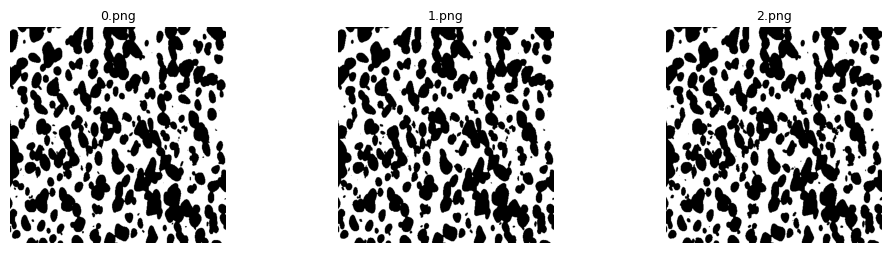

In [25]:
#Show some images from the pool
fig, axs = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, ww in zip(axs, range(3)):
    ax.imshow(image_pool[ww, :, :, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(image_filenames[ww], fontsize=9)
    ax.axis('off')
plt.show()

In [26]:
#Create training and test set
#
#For this purpose, we use this function: utilities.create_set(pool_image_array=None, pool_label_array=None, no_training_samples=None, no_test_samples=None, documentation_path=None)
#For an autoencoder, the input and the target are the same image --> we pass the image pool twice
#The split is documented in results/training_test_splits.csv (index refers to the sorted image filenames)
no_training_samples = int(TRAINING_FRACTION * len(image_pool))

training_images, _, test_images, _ = utilities.create_set(pool_image_array=image_pool, pool_label_array=image_pool,
                                                          no_training_samples=no_training_samples,
                                                          documentation_path='results')

splits = pandas.read_csv('results/training_test_splits.csv')
training_index = splits[splits['split']=='training']['dataset'].values
test_index     = splits[splits['split']=='test']['dataset'].values
print("Training images: " + str(training_images.shape[0]) + ", test images: " + str(test_images.shape[0]))

Training images: 2, test images: 1


In [27]:
#==================================================================================
#Part A: training the autoencoder
#==================================================================================
#
#For defining a new CAE, we use this function: model.create_cae2D(training_labels, latent_dim=2, encoder_depth=2, number_filters_at_first_encoder=32,
#                                                                number_last_neurons=16, learning_rate=1E-3, distributed=False, info=False)
#If you install the GPU version of this library, you can set "distributed=True" which will activate Horovod library to allow training with GPU
#"info=True" will give you a summary of the encoder and the decoder
cae = model.create_cae2D(training_images,
                         latent_dim=LATENT_DIM,
                         encoder_depth=ENCODER_DEPTH,
                         number_filters_at_first_encoder=NUMBER_FILTERS_AT_FIRST_ENCODER,
                         number_last_neurons=NUMBER_LAST_NEURONS,
                         learning_rate=LEARNING_RATE,
                         distributed=False,
                         info=True)

This is your model's encoder:
Model: "encoding"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 512, 512, 1)]     0         
                                                                 
 conv2d_6 (Conv2D)           (None, 512, 512, 16)      160       
                                                                 
 batch_normalization_12 (Ba  (None, 512, 512, 16)      64        
 tchNormalization)                                               
                                                                 
 activation_12 (Activation)  (None, 512, 512, 16)      0         
                                                                 
 conv2d_7 (Conv2D)           (None, 512, 512, 16)      2320      
                                                                 
 batch_normalization_13 (Ba  (None, 512, 512, 16)      64        
 tchNormalization)          

 input_1 (InputLayer)        [(None, 64, 64, 1)]       0         


 conv2d (Conv2D)             (None, 64, 64, 16)        160       


 batch_normalization (Batch  (None, 64, 64, 16)        64        


 Normalization)                                                  


...

Total params: 388225 (1.48 MB)


Trainable params: 387777 (1.48 MB)


Non-trainable params: 448 (1.75 KB)


_________________________________________________________________


None


In [ ]:
#Training
#
#For this purpose, we use this function: trainer.train_cae2D(training_images, training_labels, model, batch_size, epochs, distributed=False, save_path=None)
#Again, images and labels are the same for an autoencoder
#save_path saves the encoder ("trained_encoder.tf"), the decoder ("trained_decoder.tf"), and the loss history ("training_log.csv")
start = time.time()
trained_cae = trainer.train_cae2D(training_images, training_images,
                                  cae, batch_size=BATCH_SIZE, epochs=EPOCHS,
                                  distributed=False,
                                  save_path='results')
print("Training time: " + str(round(time.time() - start, 2)) + " s")

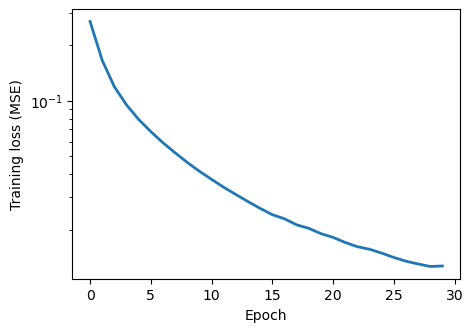

In [32]:
#Show the training loss
#If the loss is still decreasing at the end, increase EPOCHS
training_log = pandas.read_csv('results/training_log.csv')

plt.figure(figsize=(5,3.5))
plt.plot(training_log['epoch'], training_log['loss'], linewidth=2)
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Training loss (MSE)')
plt.show()

In [35]:
#Reconstruction quality on the test set
#
#For binary images, we use the built-in metrics (they threshold the reconstruction at 0.5):
#    trainer.calculate_cae2D_metric(test_images, test_labels, model, criterion='l2_norm' or 'l1_norm', save_path=None) --> "test_error.txt"
#    trainer.calculate_cae2D_jaccard(test_images, test_labels, model, save_path=None)                                 --> "jaccard.txt" (1 = perfect overlap)
#For grayscale images, thresholding is not meaningful, so we calculate the RMSE of the continuous reconstruction
#Note that the current model selection and number of training samples are inoptimal, it is only for demonstration purpose
if(BINARY_IMAGES==True):
    test_error = trainer.calculate_cae2D_metric(test_images, test_images, trained_cae, criterion='l2_norm', save_path='results')
    jaccard    = trainer.calculate_cae2D_jaccard(test_images, test_images, trained_cae, save_path='results')
    print("Test error (L2-norm): " + str(round(test_error, 4)))
    print("Mean Jaccard index: " + str(round(numpy.mean(jaccard), 4)))
else:
    reconstructed = trained_cae.decoder(trained_cae.encoder(test_images)).numpy()
    test_error = numpy.sqrt(numpy.mean((reconstructed - test_images)**2))
    numpy.savetxt('results/test_error.txt', [test_error])
    print("Test error (RMSE): " + str(round(test_error, 4)))

Test error (L2-norm): 0.4743
Mean Jaccard index: 0.5853


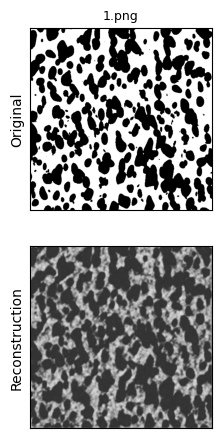

In [48]:
#Visual comparison: original vs reconstruction for 5 test images
n_show = min(5, len(test_images))
reconstructed = trained_cae.decoder(trained_cae.encoder(test_images[:n_show])).numpy()

#squeeze=False keeps axs as a 2D array, even when there is only 1 column
fig, axs = plt.subplots(2, n_show, figsize=(2.4 * n_show + 1, 5.2), squeeze=False)
for ww in range(n_show):
    axs[0, ww].imshow(test_images[ww, :, :, 0], cmap='gray', vmin=0, vmax=1)
    axs[1, ww].imshow(reconstructed[ww, :, :, 0], cmap='gray', vmin=0, vmax=1)
    axs[0, ww].set_title(image_filenames[test_index[ww]], fontsize=9)
axs[0, 0].set_ylabel('Original')
axs[1, 0].set_ylabel('Reconstruction')
for ax in axs.flatten():
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

In [49]:
#==================================================================================
#Part B: using the encoder for reduction
#==================================================================================
#
#The encoder turns every image into LATENT_DIM numbers. This is the reduced representation that you can store, analyze, cluster,
#or use as the output of a regression model (see Part C)
#We save the latent codes of all images together with their filenames
latent_codes = trained_cae.encoder(image_pool).numpy()

latent_table = pandas.DataFrame(latent_codes, columns=['z' + str(ii) for ii in range(LATENT_DIM)])
latent_table.insert(0, 'filename', image_filenames)
latent_table.to_csv('results/latent_codes.csv', index=False)
numpy.save('results/latent_codes.npy', latent_codes)

print("Original size per image: " + str(IMAGE_SIZE * IMAGE_SIZE) + " pixels")
print("Reduced size per image: " + str(LATENT_DIM) + " numbers")
print("Compression factor: " + str(int(IMAGE_SIZE * IMAGE_SIZE / LATENT_DIM)))
latent_table.head()

Original size per image: 262144 pixels
Reduced size per image: 8 numbers
Compression factor: 32768


,filename,z0,z1,z2,z3,z4,z5,z6,z7
0,0.png,-721.905273,148.374191,-142.923370,3.052563,127.076057,-279.743073,-53.577358,357.472473
1,1.png,-722.206543,148.396408,-142.913376,3.125424,127.123817,-279.785339,-53.709667,357.608398
2,2.png,-722.528687,148.396820,-142.827820,3.285031,127.139488,-279.774933,-53.960049,357.747253


In [52]:
#Loading the trained encoder and decoder later (e.g., in another notebook)
#
#For this purpose, we use this function: model.load_existing_cae2D(encoder_kerasname=None, decoder_kerasname=None, info=False)
encoder, decoder = model.load_existing_cae2D(encoder_kerasname='results/trained_encoder.tf',
                                             decoder_kerasname='results/trained_decoder.tf')

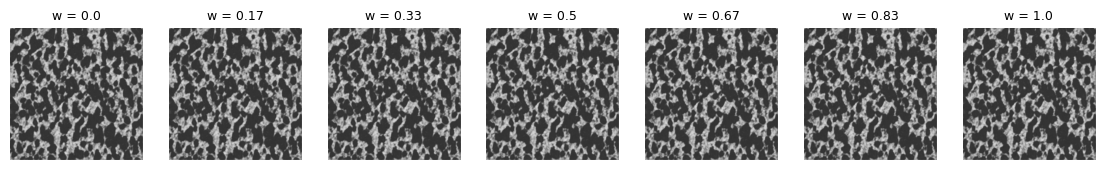

In [55]:
#Exploring the latent space: walking from one image to another
#
#We encode two images, interpolate linearly between their latent codes, and decode every step
#Smooth transitions indicate a well-organized latent space, which is what you want for regression in Part C
#Start: the first test image. End: the second test image, or the first training image if there is only 1 test image
start_image = test_images[0:1]                       #[0:1] keeps the batch dimension --> (1, size, size, 1)
if(len(test_images) > 1):
    end_image = test_images[1:2]
else:
    end_image = training_images[0:1]

z_start = encoder(start_image).numpy()
z_end   = encoder(end_image).numpy()
weights = numpy.linspace(0, 1, 7)
z_path  = numpy.asarray([(1 - ww) * z_start[0] + ww * z_end[0] for ww in weights])
decoded_path = decoder(z_path).numpy()

fig, axs = plt.subplots(1, len(weights), figsize=(14, 2.4))
for ax, ww, img in zip(axs, weights, decoded_path):
    ax.imshow(img[:, :, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title('w = ' + str(round(ww, 2)), fontsize=9)
    ax.axis('off')
plt.show()

In [25]:
#Tips for your own dataset:
#1. Start with IMAGE_SIZE=64 and a few hundred images to check that everything runs, then increase the size
#2. Try several LATENT_DIM values (e.g., 2, 4, 8, 16) and compare the test error --> choose the smallest one that is good enough
#3. If the reconstruction is blurry, train longer (EPOCHS) or increase NUMBER_FILTERS_AT_FIRST_ENCODER
#4. For 128 or 256 pixels, use ENCODER_DEPTH=4 (or 5) to keep the number of trainable parameters manageable